# Transformers


#### A Transformer is a deep learning architecture designed to process sequences of text using self-attention.

- Transformers are the foundation of many modern NLP models, including BERT, GPT, and T5.

- Before Transformers, we used models such as RNNs and LSTMs for NLP tasks.

<img src="https://drive.google.com/thumbnail?id=1unPqGaKftHxp37-F99Bg6hJzFbQdCGC7&sz=w1000" width="700">

In [1]:
%pip -q install transformers torch matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: D:\NLP_Labs\.venv\Scripts\python.exe -m pip install --upgrade pip


## 1. Load a Transformer

We use **DistilBERT**, a  Transformer fine-tuned for positive/negative sentiment classification.

In [2]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch

model_name = "distilbert-base-uncased-finetuned-sst-2-english"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForSequenceClassification.from_pretrained(model_name)
model.eval()

# Look inside the Transformer architecture.
print("Transformer layers:", model.config.n_layers)
print("Attention heads per layer:", model.config.n_heads)
print("Hidden size:", model.config.dim)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Transformer layers: 6
Attention heads per layer: 12
Hidden size: 768



<img src="https://drive.google.com/thumbnail?id=1v2dRK1KR_ydZOknjj8Xv8_wjOdXleDYs&sz=w1000" width="500">

## 2. Tokenizing the text

In [3]:
sentence = "The movie was not good."

# Tokenization: converts text into token IDs
inputs = tokenizer(sentence, return_tensors="pt")

# [CLS] = start token, [SEP] = end token
tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

print("Tokens:", tokens)

Tokens: ['[CLS]', 'the', 'movie', 'was', 'not', 'good', '.', '[SEP]']


## 3. Embeddings and self-attention

Each token ID becomes a **vector (embedding)**. Inside each Transformer layer, **self-attention** lets a token use information from other tokens in the same sentence.

In [4]:
import torch

# Enable attention weights
model.set_attn_implementation("eager")

with torch.no_grad():
    embeddings = model.distilbert.embeddings(inputs["input_ids"])
    outputs = model(**inputs, output_attentions=True)

# Attention from the first layer and first head
attention = outputs.attentions[0][0, 0]

print("Embeddings shape:", embeddings.shape)
print("Attention shape:", attention.shape)
print("Tokens:", tokens)
print("Attention weights:\n", attention)

Embeddings shape: torch.Size([1, 8, 768])
Attention shape: torch.Size([8, 8])
Tokens: ['[CLS]', 'the', 'movie', 'was', 'not', 'good', '.', '[SEP]']
Attention weights:
 tensor([[0.1145, 0.0938, 0.0681, 0.0701, 0.0596, 0.0800, 0.1593, 0.3546],
        [0.4147, 0.0793, 0.0481, 0.1018, 0.1084, 0.0805, 0.0789, 0.0883],
        [0.1634, 0.0327, 0.0975, 0.0403, 0.1819, 0.1402, 0.0866, 0.2574],
        [0.2882, 0.1014, 0.0504, 0.0669, 0.2180, 0.1009, 0.1231, 0.0511],
        [0.3612, 0.0501, 0.0696, 0.1200, 0.0642, 0.1304, 0.0953, 0.1092],
        [0.3065, 0.0469, 0.1175, 0.1915, 0.0630, 0.0555, 0.1120, 0.1071],
        [0.3505, 0.0935, 0.0572, 0.0753, 0.0972, 0.0964, 0.1165, 0.1135],
        [0.3513, 0.1019, 0.0318, 0.0541, 0.1036, 0.0607, 0.0755, 0.2210]])


## 4. Classification: From Transformer to prediction

The Transformer produces contextual representations. The **classification head** turns them into two scores (*logits*). **Softmax** converts these into probabilities that sum to 1.

In [5]:
# Get prediction scores from the Transformer
with torch.no_grad():
    logits = model(**inputs).logits

# Convert scores into probabilities
probs = torch.softmax(logits, dim=1)[0]

# Display the prediction
prediction = probs.argmax().item()

print("Prediction:", model.config.id2label[prediction])
print("Confidence:", round(probs[prediction].item(), 3))


Prediction: NEGATIVE
Confidence: 1.0



### Task: Exploring Transformer Layers and Attention Heads

Load the pretrained **`bert-base-uncased`** model using Hugging Face Transformers.

1. Write code to print the number of Transformer layers and the number of attention heads per layer.
2. Calculate and print the total number of attention heads across all Transformer layers.
3. Using the sentence `"Transformers use self-attention to understand language."`, extract the attention weights from the **third Transformer layer and second attention head**.
4. Explain what the rows and columns of the attention matrix represent.

## Task 1 & 2 — The architecture

The three numbers are in `bert.config`. BERT names its dimensions differently from the DistilBERT
the handout loaded above — `num_hidden_layers` / `num_attention_heads` / `hidden_size`, not
`n_layers` / `n_heads` / `dim` — so section 1's cell cannot be reused as it stands.


In [6]:
from transformers.utils import logging
from transformers import AutoModel, AutoTokenizer

# The checkpoint carries a masked-LM head that a bare encoder ignores, and
# transformers 5 reports those cls.* weights as "unexpected" on load. That is
# the expected outcome here, not a damaged download.
logging.set_verbosity_error()
logging.disable_progress_bar()

name = "bert-base-uncased"
bert_tokenizer = AutoTokenizer.from_pretrained(name)

# sdpa is the default attention backend on transformers 5.x and it cannot return
# weights. Asking for eager is what makes output_attentions=True work below.
bert = AutoModel.from_pretrained(name, attn_implementation="eager")
bert.eval()

n_layers = bert.config.num_hidden_layers
n_heads = bert.config.num_attention_heads
hidden = bert.config.hidden_size

# Task 1 — layers and heads per layer
print("Transformer layers:", n_layers)
print("Attention heads per layer:", n_heads)

# Task 2 — every head in the model
print("Total attention heads:", n_layers * n_heads)

# The same three facts the handout printed for DistilBERT, for comparison.
print(f"Hidden size: {hidden} -> {hidden // n_heads} dimensions per head")
print("Parameters:", f"{sum(p.numel() for p in bert.parameters()):,}")


Transformer layers: 12
Attention heads per layer: 12
Total attention heads: 144
Hidden size: 768 -> 64 dimensions per head
Parameters: 109,482,240


#### Answer — 12 layers, 12 heads, 144 in total

| | DistilBERT (section 1) | `bert-base-uncased` (task) |
|---|---|---|
| Transformer layers | 6 | **12** |
| Attention heads per layer | 12 | **12** |
| Heads in total | 72 | **144** |
| Hidden size | 768 | 768 |
| Dimensions per head | 64 | 64 |
| Parameters | 67M | 109M |

The 144 is layers × heads, and it is also the number of separate attention matrices the model
applies to one sentence: each head owns one `tokens × tokens` table, and the heads run in parallel
inside their layer. The extra parameters over DistilBERT are mostly more stacks of the same block —
same width, twice the depth.


## Task 3 — Layer 3, head 2

"Third layer, second head" in human counting is `attentions[2][0, 1]` in torch indexing: the
`attentions` tuple is per layer, and each entry is `(batch, heads, tokens, tokens)`.


In [7]:
import pandas as pd
import torch

sentence = "Transformers use self-attention to understand language."

inputs = bert_tokenizer(sentence, return_tensors="pt")
tokens = bert_tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

with torch.no_grad():
    outputs = bert(**inputs, output_attentions=True)

layer, head = 2, 1                       # third layer, second head
attention = outputs.attentions[layer][0, head]

print("Tokens:", tokens)
print("Attention shape:", tuple(attention.shape))
print("Layers of weights available:", len(outputs.attentions))
print("Heads per layer:", outputs.attentions[0].shape[1])

# A softmax over the 11 columns, so every row has to sum to 1. If it did not,
# we would be holding the wrong tensor.
print("Row sums:", [round(v, 4) for v in attention.sum(dim=1).tolist()])

# Each row is one query token; the column it puts its largest weight on is the
# token it reads most.
for token, row in zip(tokens, attention):
    top = int(row.argmax())
    print(f"  {token:<14} reads {tokens[top]:<14} {row[top]:.2f}")

# The transpose reading: how much weight each token receives from the sentence.
print("\nWeight received per token (column sums):")
print(pd.Series(attention.sum(dim=0).numpy(), index=tokens).round(2).to_string())


Tokens: ['[CLS]', 'transformers', 'use', 'self', '-', 'attention', 'to', 'understand', 'language', '.', '[SEP]']
Attention shape: (11, 11)
Layers of weights available: 12
Heads per layer: 12
Row sums: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
  [CLS]          reads [CLS]          0.73
  transformers   reads [CLS]          0.89
  use            reads transformers   0.57
  self           reads [CLS]          0.34
  -              reads self           0.64
  attention      reads transformers   0.54
  to             reads use            0.62
  understand     reads [CLS]          0.43
  language       reads use            0.43
  .              reads [CLS]          0.66
  [SEP]          reads [CLS]          0.83

Weight received per token (column sums):
[CLS]           4.41
transformers    1.30
use             1.19
self            0.73
-               0.42
attention       0.38
to              0.60
understand      0.49
language        0.14
.               0.31
[SEP]           1.

In [8]:
# Print the whole matrix, and then draw it: a heatmap is the only way to see
# 121 numbers at once.
matrix = pd.DataFrame(attention.numpy(), index=tokens, columns=tokens).round(3)
display(matrix)


,[CLS],transformers,use,self,-,attention,to,understand,language,.,[SEP]
[CLS],0.732,0.008,0.011,0.006,0.017,0.007,0.010,0.012,0.006,0.039,0.155
transformers,0.889,0.005,0.034,0.000,0.003,0.005,0.001,0.001,0.000,0.005,0.057
use,0.143,0.569,0.005,0.035,0.041,0.068,0.090,0.000,0.005,0.009,0.034
self,0.340,0.073,0.002,0.000,0.202,0.081,0.064,0.026,0.002,0.028,0.183
-,0.143,0.070,0.071,0.639,0.012,0.013,0.003,0.003,0.014,0.009,0.022
attention,0.113,0.545,0.012,0.020,0.111,0.010,0.072,0.000,0.000,0.016,0.100
to,0.084,0.022,0.622,0.008,0.009,0.194,0.011,0.007,0.001,0.014,0.027
understand,0.434,0.005,0.002,0.022,0.012,0.003,0.330,0.002,0.055,0.053,0.082
language,0.051,0.001,0.429,0.002,0.004,0.001,0.005,0.398,0.006,0.041,0.062
.,0.658,0.006,0.003,0.001,0.004,0.003,0.009,0.038,0.046,0.073,0.159


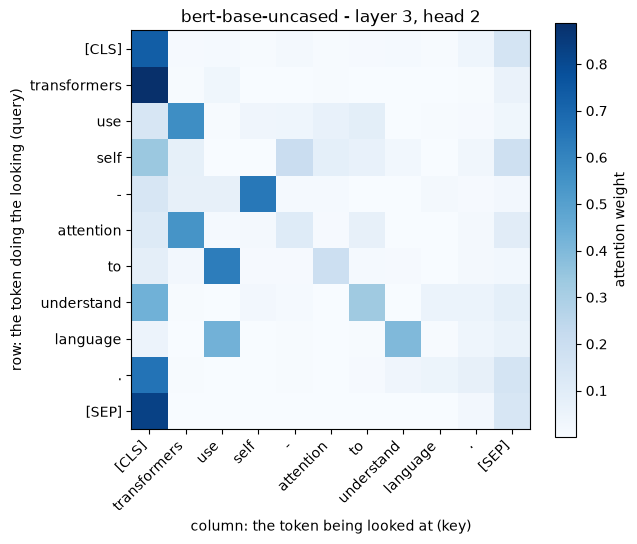

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6.5, 5.5))
image = ax.imshow(attention.numpy(), cmap="Blues")
ax.set_xticks(range(len(tokens)), tokens, rotation=45, ha="right")
ax.set_yticks(range(len(tokens)), tokens)
ax.set_xlabel("column: the token being looked at (key)")
ax.set_ylabel("row: the token doing the looking (query)")
ax.set_title("bert-base-uncased - layer 3, head 2")
fig.colorbar(image, label="attention weight")
plt.tight_layout()
plt.show()


#### Answer — what the rows and columns mean

The sentence is 11 tokens, so this head hands over an 11 × 11 table. **The rows are queries and the
columns are keys**: entry *(i, j)* is how much weight token *i* puts on token *j* when it builds its
own new representation at this layer.

| axis | is | constrained how |
|---|---|---|
| row *i* | token *i*'s attention distribution over the whole sentence — "where does this token look?" | sums to **1**: a softmax over the 11 columns |
| column *j* | how much token *j* is read by everything else — "how much influence does this token carry?" | not constrained; the column sums here run from 0.14 to 4.41 |

So a row is a recipe (a weighted average of the other tokens' value vectors, 64 numbers each), and a
column is a scoreboard of what the head is consuming. The two directions are different readings of
the same cell, which is why the matrix is not symmetric.

What this particular head does with the sentence:

| token | reads most | weight |
|---|---|---|
| `transformers` | `[CLS]` | 0.89 |
| `use` | `transformers` | 0.57 |
| `attention` | `transformers` | 0.54 |
| `to` | `use` | 0.62 |
| `-` | `self` | 0.64 |
| `[SEP]` | `[CLS]` | 0.83 |
| `[CLS]` | `[CLS]` | 0.73 |

- **`[CLS]` is a sink.** Its column sums to 4.41 of the 11 units distributed, so 40% of all the
  weight in this head goes to a token that stands for nothing beyond "the sentence starts here".
  Six of the eleven rows point at it first. This is a well-documented BERT habit and it is worth
  knowing before reading any single weight as meaning: a large share of the budget is parked on a
  position, not on a word.
- **Attention is directed.** `transformers` → `[CLS]` is 0.889; `[CLS]` → `transformers` is 0.008.
  Reading the table the wrong way round turns a strong link into a nonexistent one.
- **The tokens are subwords.** `self-attention` is three positions (`self`, `-`, `attention`), so
  "how much attention does the word *self-attention* get" is not a well-posed question; the pieces
  are separate rows and columns. `-` reads `self` at 0.64, which is the tokenizer's hyphen lining
  up the halves of the compound.
- **Layer 3 is early.** This is the third of twelve blocks, where BERT is still largely doing
  lexical and syntactic bookkeeping — the local pattern above (`to` → `use`, `attention` →
  `transformers`) fits that. The more semantic-looking heads live deeper, and 143 other matrices
  are ignored by this one picture.

**What the matrix is not.** It is one head of 144, working in 64 dimensions, and it reports the
*routing* the model chose, not the reason for its output. The Lab 11 result carries over: weights
that look meaningful are evidence about where information is read from, and no more — the check
that would make them an explanation is an intervention (killing that weight and watching the output
change), which this head is not validated against.
